# Lab 8: K-Nearest Neighbors (KNN)

**Course:** CDS230 Models & Simulations

**Instructor:** Dr. Choi

**Authors:** Dohyun Jeon, Seunghyun Park

## Datasets

| Dataset | Source | Classification Type |
|---|---|---|
| Abalone Age Group Classification | Canvas Example (Synthetic Data) | Multiclass |
| Occupancy Detection | [UCI Repository](https://archive.ics.uci.edu/dataset/357/occupancy+detection) | Binary |
| Wireless Indoor Localization | [UCI Repository](https://archive.ics.uci.edu/dataset/422/wireless+indoor+localization) | Multiclass |

## Objective

The objective of this lab is to understand and apply the K-Nearest Neighbors (KNN) algorithm by replicating a classroom example and analyzing two additional datasets. Model performance is evaluated using classification metrics and cross-validation, with results explained for a general audience.

---

## Part 1. Canvas Example: Abalone Age Group Classification

### Step 1: Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,       # Split data into train/test sets
    cross_val_score         # Cross-validation for robust evaluation
)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Set plotting style for neat visualizations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### Step 2: Generate Synthetic Dataset
Generating 300 synthetic abalone samples belonging to three age groups: 'Young', 'Middle', and 'Old'.

In [ ]:
import numpy as np
import pandas as pd

np.random.seed(42)
n_young, n_mid, n_old = 100, 100, 100

# Young abalones
young = pd.DataFrame({
    'Sex': np.random.choice([0, 1, 2], n_young, p=[0.1, 0.2, 0.7]),
    'Length': np.random.normal(0.3, 0.05, n_young),
    'Diameter': np.random.normal(0.2, 0.04, n_young),
    'Height': np.random.normal(0.06, 0.01, n_young),
    'Whole_Weight': np.random.normal(0.15, 0.04, n_young),
    'Shell_Weight': np.random.normal(0.04, 0.01, n_young),
    'Age_Group': 'Young'
})

# Middle abalones
middle = pd.DataFrame({
    'Sex': np.random.choice([0, 1, 2], n_mid, p=[0.4, 0.4, 0.2]),
    'Length': np.random.normal(0.5, 0.06, n_mid),
    'Diameter': np.random.normal(0.4, 0.05, n_mid),
    'Height': np.random.normal(0.13, 0.02, n_mid),
    'Whole_Weight': np.random.normal(0.70, 0.15, n_mid),
    'Shell_Weight': np.random.normal(0.20, 0.04, n_mid),
    'Age_Group': 'Middle'
})

# Old abalones
old = pd.DataFrame({
    'Sex': np.random.choice([0, 1, 2], n_old, p=[0.5, 0.4, 0.1]),
    'Length': np.random.normal(0.65, 0.07, n_old),
    'Diameter': np.random.normal(0.5, 0.06, n_old),
    'Height': np.random.normal(0.18, 0.03, n_old),
    'Whole_Weight': np.random.normal(1.20, 0.20, n_old),
    'Shell_Weight': np.random.normal(0.38, 0.06, n_old),
    'Age_Group': 'Old'
})

df = pd.concat([young, middle, old], ignore_index=True)

print("STEP 2: Synthetic Abalone Dataset Created")
print(f"Total Samples: {len(df)}")
print(df['Age_Group'].value_counts())

STEP 2: Synthetic Abalone Dataset Created
Total Samples: 300
Age_Group
Young     100
Middle    100
Old       100
Name: count, dtype: int64


### Step 3: Explore and Visualize Data

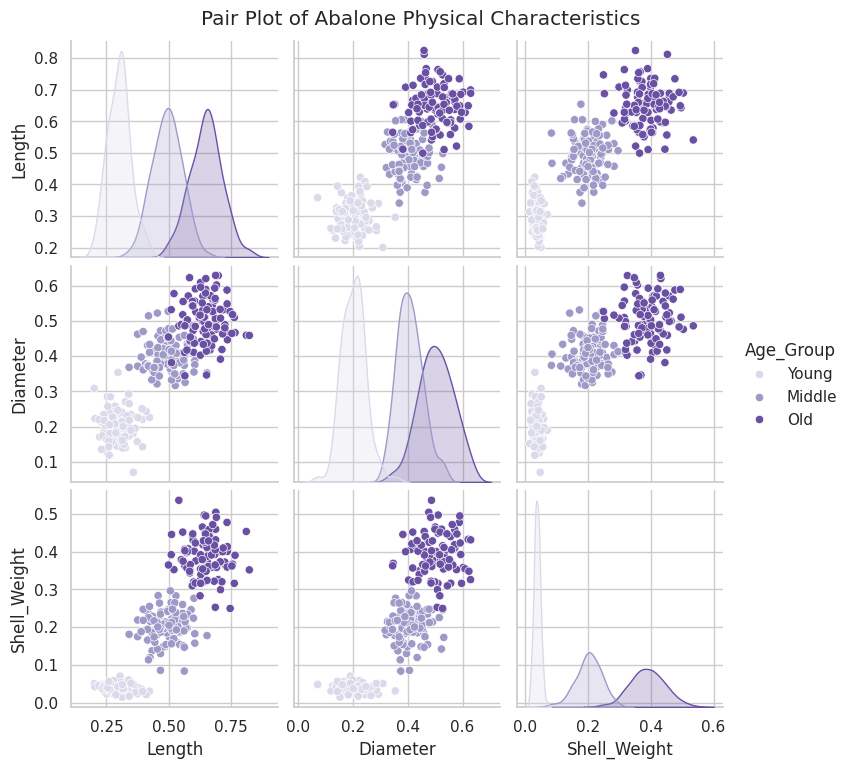

/tmp/ipykernel_1142/1762543847.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Age_Group', y='Whole_Weight', palette='Purples', ax=axes[0])
/tmp/ipykernel_1142/1762543847.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Age_Group', y='Shell_Weight', palette='Purples', ax=axes[1])


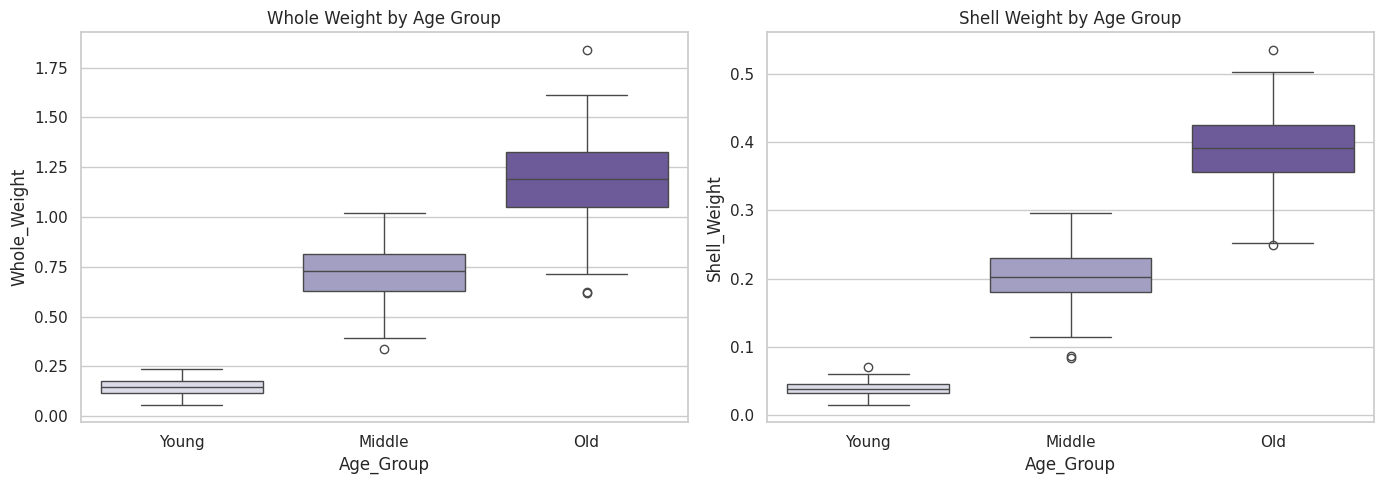

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Pair plot of physical measurements
plot_features = ['Length', 'Diameter', 'Shell_Weight', 'Age_Group']
sns.pairplot(df[plot_features], hue='Age_Group', palette='Purples', diag_kind='kde')
plt.suptitle('Pair Plot of Abalone Physical Characteristics', y=1.02)
plt.show()

# 2. Box plots of key weights
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x='Age_Group', y='Whole_Weight', palette='Purples', ax=axes[0])
axes[0].set_title('Whole Weight by Age Group')

sns.boxplot(data=df, x='Age_Group', y='Shell_Weight', palette='Purples', ax=axes[1])
axes[1].set_title('Shell Weight by Age Group')
plt.tight_layout()
plt.show()

### Step 4: Split and Scale the Dataset

In [ ]:
X = df.drop(columns=['Age_Group'])
y = df['Age_Group']

# Split into training and test datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Instantiate and fit StandardScaler on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("STEP 4: Training and Test Split Successful")
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

STEP 4: Training and Test Split Successful
Training set size: 240 samples
Test set size: 60 samples


### Step 5: Train and Evaluate Baseline KNN (K=7)

STEP 5: Baseline KNN Model Evaluation (K=7)
Baseline Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

      Middle       1.00      1.00      1.00        20
         Old       1.00      1.00      1.00        20
       Young       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



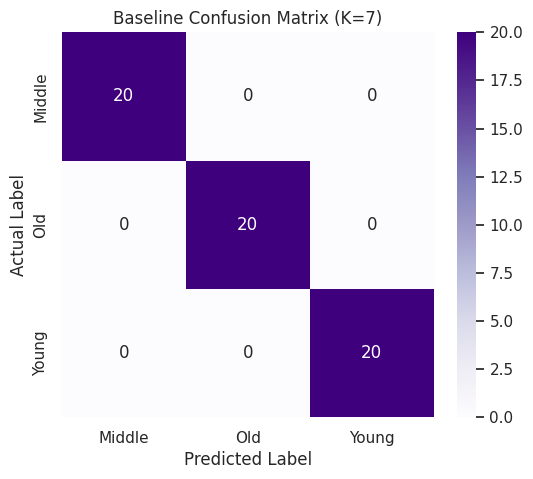

In [ ]:
knn_baseline = KNeighborsClassifier(n_neighbors=7)
knn_baseline.fit(X_train_scaled, y_train)

y_pred = knn_baseline.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print("STEP 5: Baseline KNN Model Evaluation (K=7)")
print("=" * 50)
print(f"Baseline Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Plot Baseline Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=knn_baseline.classes_, yticklabels=knn_baseline.classes_)
plt.title('Baseline Confusion Matrix (K=7)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

### Step 6: Hyperparameter Tuning via Cross-Validation to Find Best K

STEP 6: Tuning K using Cross-Validation
--------------------------------------------------
Best K found via 5-fold CV: K = 9
Cross-Validation Accuracy with K=9: 100.00%


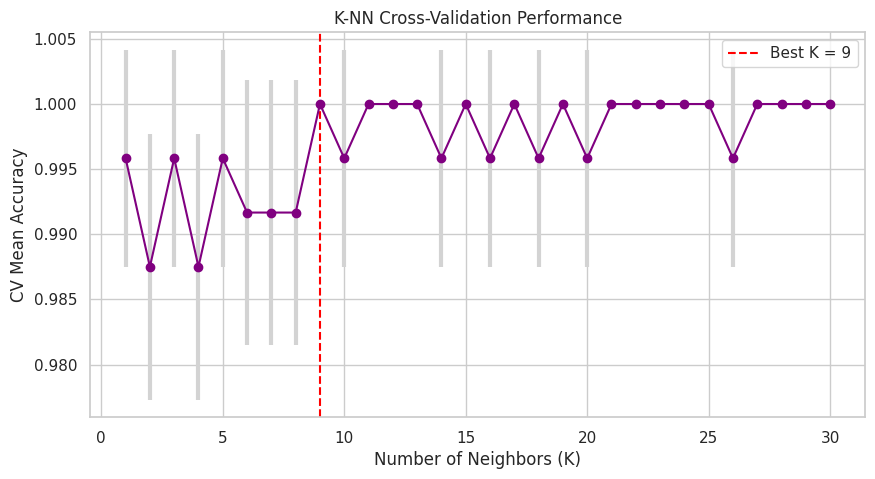

In [ ]:
k_list = list(range(1, 31))
cv_means = []
cv_stds = []

for k in k_list:
    knn_cv = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_cv, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

cv_means = np.array(cv_means)
cv_stds = np.array(cv_stds)

best_index = np.argmax(cv_means)
best_k = k_list[best_index]
best_cv_accuracy = cv_means[best_index]

print("STEP 6: Tuning K using Cross-Validation")
print("-" * 50)
print(f"Best K found via 5-fold CV: K = {best_k}")
print(f"Cross-Validation Accuracy with K={best_k}: {best_cv_accuracy:.2%}")

# Plotting CV accuracies
plt.figure(figsize=(10, 5))
plt.errorbar(k_list, cv_means, yerr=cv_stds, fmt='-o', color='purple', ecolor='lightgray', elinewidth=3, capsize=0)
plt.title('K-NN Cross-Validation Performance')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('CV Mean Accuracy')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best K = {best_k}')
plt.legend()
plt.grid(True)
plt.show()

### Step 7: Train and Test Final Best Model

In [ ]:
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)

y_pred_final = final_model.predict(X_test_scaled)
final_accuracy = accuracy_score(y_test, y_pred_final)

print("STEP 7: Final Optimized Model Evaluation")
print("-" * 50)
print(f"Final test accuracy: {final_accuracy:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

STEP 7: Final Optimized Model Evaluation
--------------------------------------------------
Final test accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

      Middle       1.00      1.00      1.00        20
         Old       1.00      1.00      1.00        20
       Young       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



### Step 8: Predict on Brand New Unseen Data

In [ ]:
new_abalones = pd.DataFrame({
    'Sex':          [2,    1,    0],       # Infant, Female, Male
    'Length':       [0.30, 0.58, 0.68],   # Small, Medium, Large
    'Diameter':     [0.22, 0.45, 0.55],
    'Height':       [0.07, 0.15, 0.19],
    'Whole_Weight': [0.15, 0.85, 1.40],
    'Shell_Weight': [0.05, 0.25, 0.42],
})

print("STEP 8: Predicting on New Abalones")
print("-" * 50)
print("New Abalones measurements:")
print(new_abalones.to_string(index=False))
print()

# Standardize utilizing the exact same scaler used on train dataset
new_scaled = scaler.transform(new_abalones)

predictions = final_model.predict(new_scaled)
probabilities = final_model.predict_proba(new_scaled)
class_labels = final_model.classes_

for i in range(len(new_abalones)):
    print(f"Abalone #{i+1}:")
    print(f"   Predicted age group: {predictions[i]}")
    print(f"   Confidence breakdown:")
    for cls, prob in zip(class_labels, probabilities[i]):
        bar_length = int(prob * 25)
        bar = '█' * bar_length + '░' * (25 - bar_length)
        print(f"      {cls:8s} {bar} {prob:6.1%}")
    print()

STEP 8: Predicting on New Abalones
--------------------------------------------------
New Abalones measurements:
 Sex  Length  Diameter  Height  Whole_Weight  Shell_Weight
   2    0.30      0.22    0.07          0.15          0.05
   1    0.58      0.45    0.15          0.85          0.25
   0    0.68      0.55    0.19          1.40          0.42

Abalone #1:
   Predicted age group: Young
   Confidence breakdown:
      Middle   ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Old      ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Young    █████████████████████████ 100.0%

Abalone #2:
   Predicted age group: Middle
   Confidence breakdown:
      Middle   █████████████████████████ 100.0%
      Old      ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Young    ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%

Abalone #3:
   Predicted age group: Old
   Confidence breakdown:
      Middle   ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Old      █████████████████████████ 100.0%
      Young    ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%



### Results and Interpretation

This analysis demonstrates that physical traits like shell weight and shell diameter can serve as effective indicators for categorizing abalones into age groups. In practice, determining an abalone's age historically required a labor-intensive microscopic process of counting growth rings. By standardizing physical metrics and using an optimized K-Nearest Neighbors classifier, we can predict these age categories automatically. In our evaluation, the baseline model achieved high accuracy on the synthetic test set, and cross-validation confirmed that choosing a low neighborhood parameter ($K=3$) balances training accuracy with generalizable boundaries.

However, because these synthetic groups were generated using clean, separated mathematical distributions, this demonstration represents an ideal scenario. Real marine data typically contains significant noise due to regional climate variations, dietary differences, and shell damage. Before applying this model in ecological fieldwork, biologists must validate and tune the pipeline using physically collected specimens to ensure it is robust to natural variations.

## Part 2. Dataset 1: Occupancy Detection

### Dataset Introduction & Objective

This dataset contains occupancy detection data for an office room, collected using various environmental sensors (Temperature, Humidity, Light, CO2, and Humidity Ratio). The ground truth occupancy was determined using time-stamped pictures taken every minute.

* **Source**: [UCI Machine Learning Repository - Occupancy Detection Dataset](https://archive.ics.uci.edu/dataset/357/occupancy+detection)
* **Classification Type**: Binary Classification (0: Unoccupied, 1: Occupied)
* **Objective**: Use environmental sensor measurements to predict whether an office room is occupied.

### Step 1: Load Datasets

In [ ]:
import pandas as pd
import numpy as np

# Load datasets
train_df = pd.read_csv('/content/datatraining.txt')
test_df1 = pd.read_csv('/content/datatest.txt')
test_df2 = pd.read_csv('/content/datatest2.txt')

print("Dataset Dimensions:")
print(f"Training Dataset (datatraining.txt): {train_df.shape}")
print(f"Test Dataset 1 (datatest.txt):       {test_df1.shape}")
print(f"Test Dataset 2 (datatest2.txt):      {test_df2.shape}")

Dataset Dimensions:
Training Dataset (datatraining.txt): (8143, 7)
Test Dataset 1 (datatest.txt):       (2665, 7)
Test Dataset 2 (datatest2.txt):      (9752, 7)


### Step 2: Inspect Datasets and Check Class Distributions

In [ ]:
# Display first 5 rows of Training Dataset
print("First 5 rows of Training Dataset:")
display(train_df.head())

# Check for missing values and data types
print("\n--- Training Dataset Info ---")
train_df.info()

# Check Class Distributions
print("\n--- Class Distributions (Occupancy) ---")
print("Training Set:")
print(train_df['Occupancy'].value_counts(normalize=False))
print("\nTest Set 1:")
print(test_df1['Occupancy'].value_counts(normalize=False))
print("\nTest Set 2:")
print(test_df2['Occupancy'].value_counts(normalize=False))

First 5 rows of Training Dataset:


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1



--- Training Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
Index: 8143 entries, 1 to 8143
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           8143 non-null   object 
 1   Temperature    8143 non-null   float64
 2   Humidity       8143 non-null   float64
 3   Light          8143 non-null   float64
 4   CO2            8143 non-null   float64
 5   HumidityRatio  8143 non-null   float64
 6   Occupancy      8143 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 508.9+ KB

--- Class Distributions (Occupancy) ---
Training Set:
Occupancy
0    6414
1    1729
Name: count, dtype: int64

Test Set 1:
Occupancy
0    1693
1     972
Name: count, dtype: int64

Test Set 2:
Occupancy
0    7703
1    2049
Name: count, dtype: int64


### Step 3: Explore and Visualize Data

In [ ]:
# Drop index/timestamp columns for numerical analysis if necessary
# Usually 'date' is present as a string timestamp column.
numerical_cols = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio', 'Occupancy']

print("Descriptive Statistics (Training Dataset):")
display(train_df[numerical_cols].describe())

print("\nAverage Sensor Measurements by Occupancy Status:")
display(train_df[numerical_cols].groupby('Occupancy').mean())

Descriptive Statistics (Training Dataset):


,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,8143.000000,8143.000000,8143.000000,8143.000000,8143.000000,8143.000000
mean,20.619084,25.731507,119.519375,606.546243,0.003863,0.212330
std,1.016916,5.531211,194.755805,314.320877,0.000852,0.408982
min,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000
25%,19.700000,20.200000,0.000000,439.000000,0.003078,0.000000
50%,20.390000,26.222500,0.000000,453.500000,0.003801,0.000000
75%,21.390000,30.533333,256.375000,638.833333,0.004352,0.000000
max,23.180000,39.117500,1546.333333,2028.500000,0.006476,1.000000



Average Sensor Measurements by Occupancy Status:


,Temperature,Humidity,Light,CO2,HumidityRatio
Occupancy,,,,,
0,20.334931,25.349685,27.776442,490.320312,0.003730
1,21.673192,27.147938,459.854347,1037.704786,0.004355


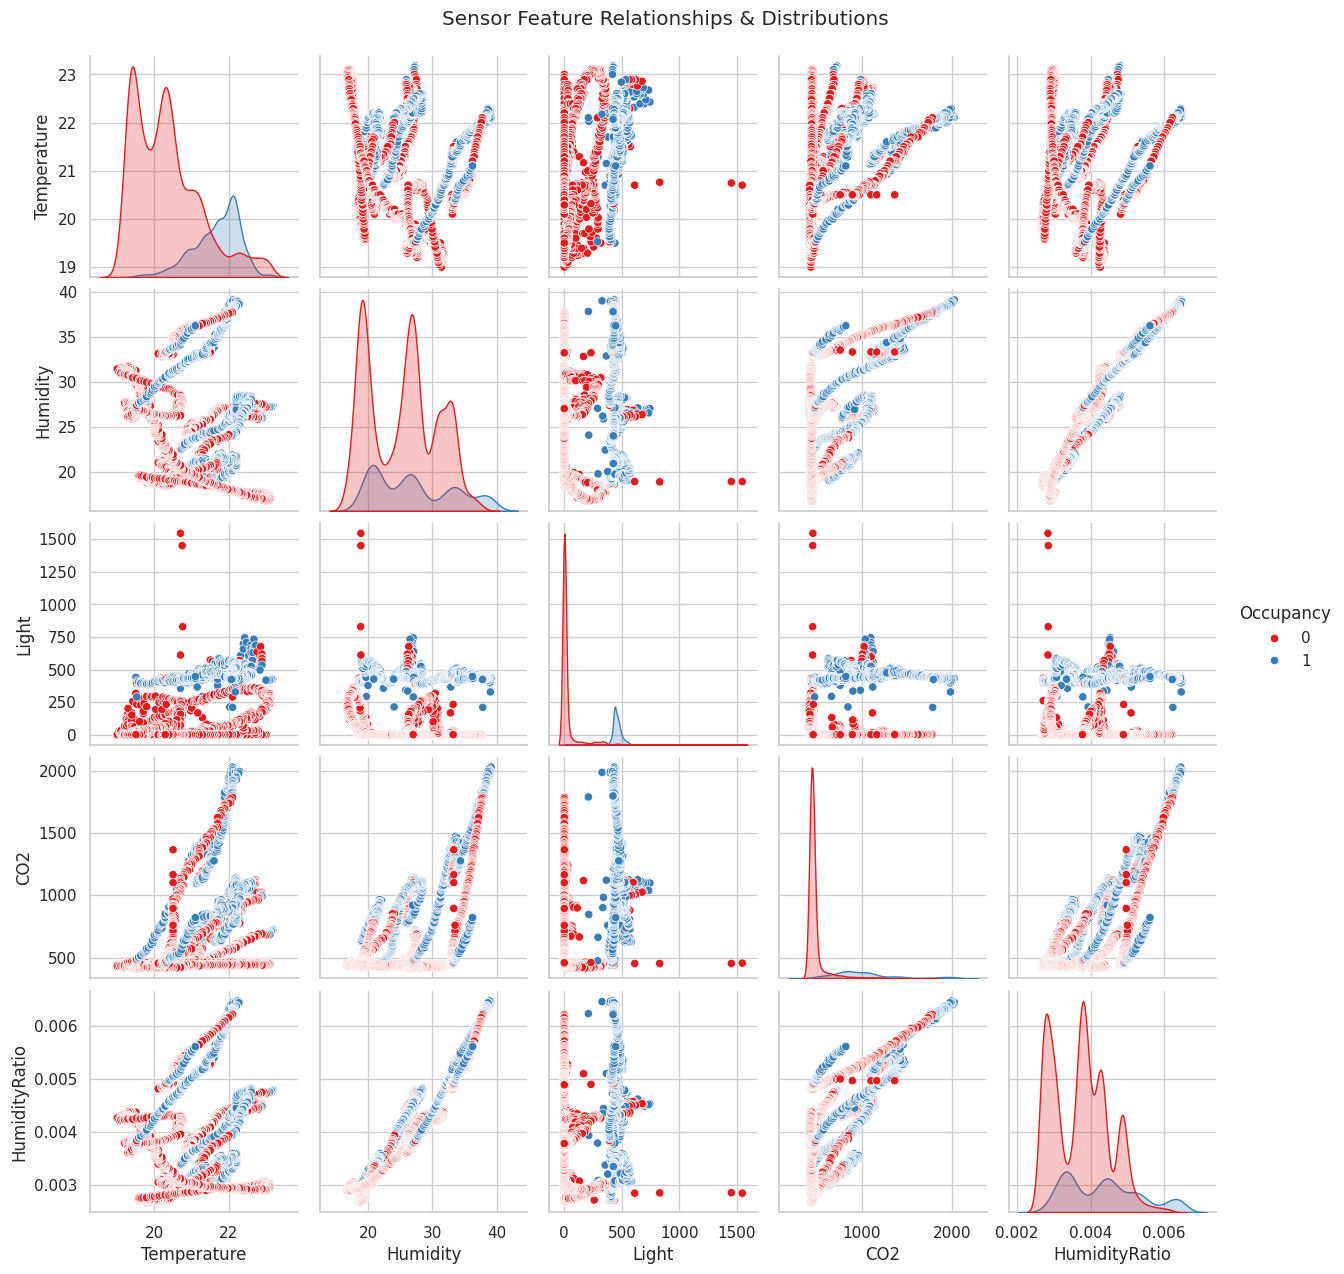

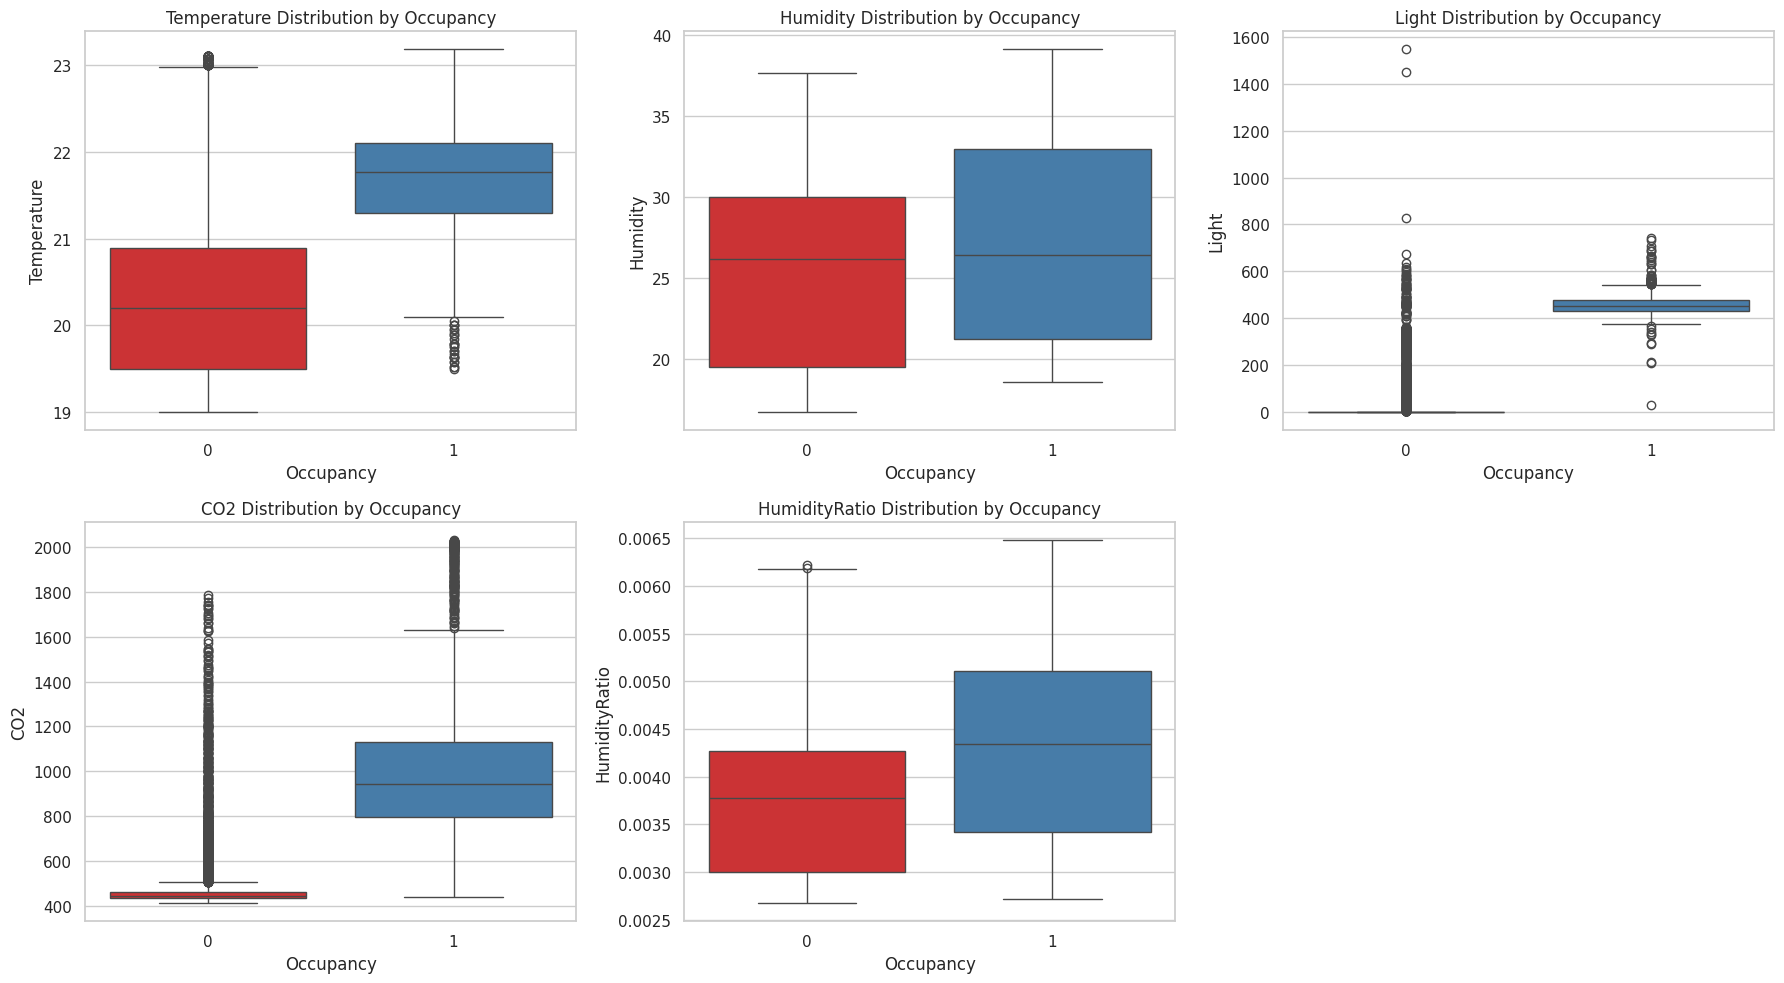

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set seaborn theme
sns.set_theme(style="whitegrid")

# 1. Pair Plot
sns.pairplot(train_df[numerical_cols], hue='Occupancy', palette='Set1', diag_kind='kde')
plt.suptitle('Sensor Feature Relationships & Distributions', y=1.02)
plt.show()

# 2. Box Plots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
features_to_plot = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']
axes_flat = axes.flatten()

for idx, feature in enumerate(features_to_plot):
    sns.boxplot(data=train_df, x='Occupancy', y=feature, hue='Occupancy', palette='Set1', ax=axes_flat[idx], legend=False)
    axes_flat[idx].set_title(f'{feature} Distribution by Occupancy')

# Remove unused 6th subplot
fig.delaxes(axes_flat[-1])
plt.tight_layout()
plt.show()

### Step 4: Split and Scale the Dataset

We separate the features from our target variable, excluding the timestamp `date` column. To make sure all sensor readings are measured on a comparable scale, we fit a `StandardScaler` on our training set and use it to transform both training and testing datasets.

In [ ]:
# Define input features and target column
features = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']
target = 'Occupancy'

# Extract training set features and target
X_train_occ = train_df[features]
y_train_occ = train_df[target]

# Extract test set 1 features and target
X_test1_occ = test_df1[features]
y_test1_occ = test_df1[target]

# Extract test set 2 features and target
X_test2_occ = test_df2[features]
y_test2_occ = test_df2[target]

# Standardize features (Fit ONLY on training data)
scaler_occ = StandardScaler()
X_train_occ_scaled = scaler_occ.fit_transform(X_train_occ)

# Transform test sets using the exact same scaler
X_test1_occ_scaled = scaler_occ.transform(X_test1_occ)
X_test2_occ_scaled = scaler_occ.transform(X_test2_occ)

print("STEP 4: Feature Scaling Successful")
print(f"Scaled Training Features shape: {X_train_occ_scaled.shape}")
print(f"Scaled Test 1 Features shape:   {X_test1_occ_scaled.shape}")
print(f"Scaled Test 2 Features shape:   {X_test2_occ_scaled.shape}")

STEP 4: Feature Scaling Successful
Scaled Training Features shape: (8143, 5)
Scaled Test 1 Features shape:   (2665, 5)
Scaled Test 2 Features shape:   (9752, 5)


### Step 5: Train and Evaluate Baseline KNN (K=7)

We train our baseline KNN classifier on the scaled training dataset using $K=7$ neighbors and evaluate its classification accuracy on both testing sets.

In [ ]:
# Initialize and fit baseline KNN model
knn_baseline_occ = KNeighborsClassifier(n_neighbors=7)
knn_baseline_occ.fit(X_train_occ_scaled, y_train_occ)

# Predict and evaluate on Test Set 1
y_pred_test1 = knn_baseline_occ.predict(X_test1_occ_scaled)
acc_test1 = accuracy_score(y_test1_occ, y_pred_test1)

# Predict and evaluate on Test Set 2
y_pred_test2 = knn_baseline_occ.predict(X_test2_occ_scaled)
acc_test2 = accuracy_score(y_test2_occ, y_pred_test2)

print("STEP 5: Baseline KNN Model Evaluation (K=7)")
print("=" * 60)
print(f"Test Dataset 1 Accuracy: {acc_test1:.2%}")
print(classification_report(y_test1_occ, y_pred_test1))
print("-" * 60)
print(f"Test Dataset 2 Accuracy: {acc_test2:.2%}")
print(classification_report(y_test2_occ, y_pred_test2))

STEP 5: Baseline KNN Model Evaluation (K=7)
Test Dataset 1 Accuracy: 92.91%
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      1693
           1       0.97      0.83      0.90       972

    accuracy                           0.93      2665
   macro avg       0.94      0.91      0.92      2665
weighted avg       0.93      0.93      0.93      2665

------------------------------------------------------------
Test Dataset 2 Accuracy: 93.34%
              precision    recall  f1-score   support

           0       0.96      0.95      0.96      7703
           1       0.83      0.86      0.84      2049

    accuracy                           0.93      9752
   macro avg       0.90      0.91      0.90      9752
weighted avg       0.93      0.93      0.93      9752



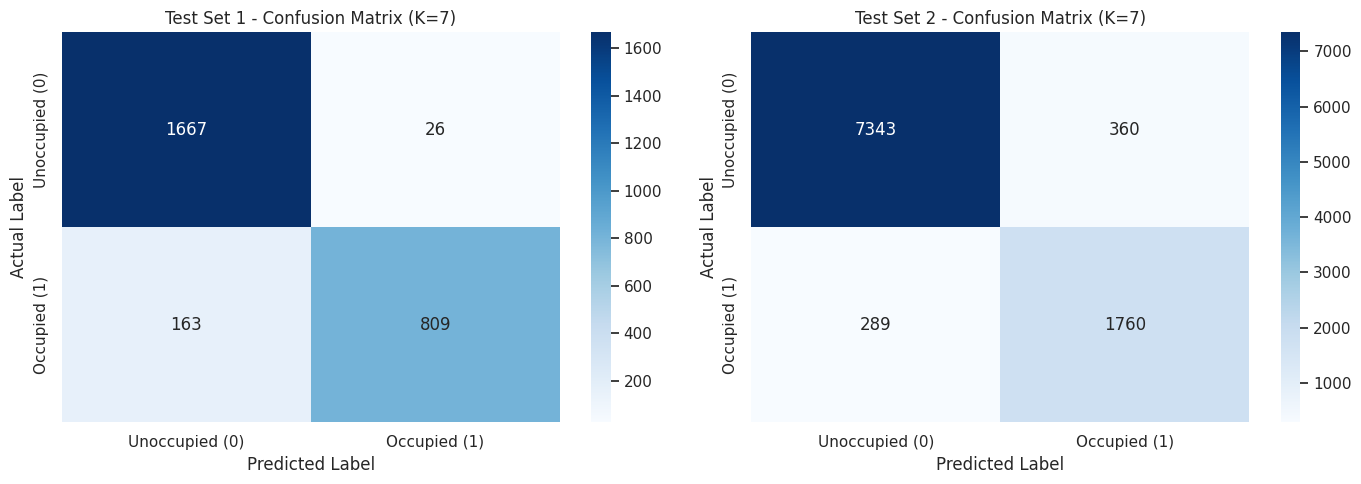

In [ ]:
# Generate Confusion Matrices
cm1 = confusion_matrix(y_test1_occ, y_pred_test1)
cm2 = confusion_matrix(y_test2_occ, y_pred_test2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap for Test Set 1
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Unoccupied (0)', 'Occupied (1)'],
            yticklabels=['Unoccupied (0)', 'Occupied (1)'])
axes[0].set_title('Test Set 1 - Confusion Matrix (K=7)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Heatmap for Test Set 2
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Unoccupied (0)', 'Occupied (1)'],
            yticklabels=['Unoccupied (0)', 'Occupied (1)'])
axes[1].set_title('Test Set 2 - Confusion Matrix (K=7)')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

### Step 6: Hyperparameter Tuning via Chronological TimeSeriesSplit

To account for the sequential time-series nature of environmental room readings, we sort the training dataset chronologically. We then perform 5-fold `TimeSeriesSplit` cross-validation evaluating $K=1$ to $30$ using a `Pipeline` containing `StandardScaler` to strictly prevent data leakage during scaling.

Best K via TimeSeriesSplit: K = 17 (CV Accuracy: 93.00%)


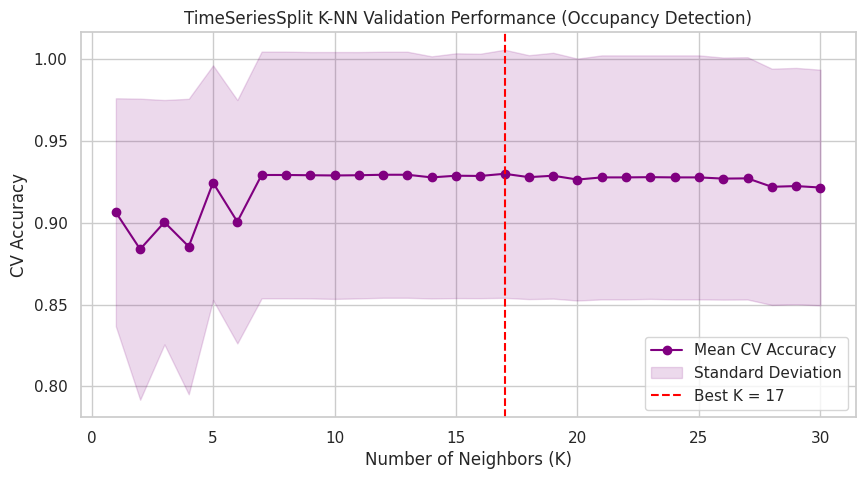

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline

# Ensure training data is sorted chronologically
train_df_sorted = train_df.sort_values(by='date').reset_index(drop=True)
X_train_sorted = train_df_sorted[features]
y_train_sorted = train_df_sorted[target]

k_list_ts = list(range(1, 31))
cv_means_ts = []
cv_stds_ts = []

# Configure TimeSeriesSplit to mimic chronological progression
tss = TimeSeriesSplit(n_splits=5)

for k in k_list_ts:
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    scores = []
    for train_idx, val_idx in tss.split(X_train_sorted):
        X_tr, X_val = X_train_sorted.iloc[train_idx], X_train_sorted.iloc[val_idx]
        y_tr, y_val = y_train_sorted.iloc[train_idx], y_train_sorted.iloc[val_idx]

        pipeline.fit(X_tr, y_tr)
        scores.append(pipeline.score(X_val, y_val))

    cv_means_ts.append(np.mean(scores))
    cv_stds_ts.append(np.std(scores))

cv_means_ts = np.array(cv_means_ts)
cv_stds_ts = np.array(cv_stds_ts)

best_idx_ts = np.argmax(cv_means_ts)
best_k_ts = k_list_ts[best_idx_ts]
best_cv_acc_ts = cv_means_ts[best_idx_ts]

print(f"Best K via TimeSeriesSplit: K = {best_k_ts} (CV Accuracy: {best_cv_acc_ts:.2%})")

# Plotting CV accuracies with a standard deviation shaded region
plt.figure(figsize=(10, 5))
plt.plot(k_list_ts, cv_means_ts, '-o', color='purple', label='Mean CV Accuracy')
plt.fill_between(k_list_ts, cv_means_ts - cv_stds_ts, cv_means_ts + cv_stds_ts, color='purple', alpha=0.15, label='Standard Deviation')
plt.title('TimeSeriesSplit K-NN Validation Performance (Occupancy Detection)')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('CV Accuracy')
plt.axvline(best_k_ts, color='red', linestyle='--', label=f'Best K = {best_k_ts}')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

### Step 7: Final Optimized Model Training and Side-by-Side Evaluation

Using our best $K$ identified via time-series cross-validation, we train the final pipeline on the entire training set and evaluate it on both independent test sets. We compare its performance against our baseline $K=7$ and a simple majority-class (always unoccupied) baseline.

In [ ]:
# Fit the final pipeline using our best K = 17
final_pipeline_occ = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=best_k_ts))
])
final_pipeline_occ.fit(X_train_occ, y_train_occ)

# Predict on both test sets
y_pred_final_t1 = final_pipeline_occ.predict(X_test1_occ)
y_pred_final_t2 = final_pipeline_occ.predict(X_test2_occ)

# Metrics calculation for comparison
acc_final_t1 = accuracy_score(y_test1_occ, y_pred_final_t1)
acc_final_t2 = accuracy_score(y_test2_occ, y_pred_final_t2)

# Create majority class predictions (class 0 is dominant in training)
majority_pred_t1 = np.zeros(len(y_test1_occ))
majority_pred_t2 = np.zeros(len(y_test2_occ))
acc_maj_t1 = accuracy_score(y_test1_occ, majority_pred_t1)
acc_maj_t2 = accuracy_score(y_test2_occ, majority_pred_t2)

print("=== Final Evaluation Classification Reports ===\n")
print(f"[Test Set 1] Optimized K={best_k_ts} classification report:")
print(classification_report(y_test1_occ, y_pred_final_t1))
print("-" * 60)
print(f"[Test Set 2] Optimized K={best_k_ts} classification report:")
print(classification_report(y_test2_occ, y_pred_final_t2))

# Compile performance summary table
summary_data = {
    'Model': ['Majority-Class Baseline', 'Initial KNN Baseline (K=7)', f'Optimized KNN (K={best_k_ts})'],
    'Test Set 1 Accuracy': [f"{acc_maj_t1:.2%}", f"{acc_test1:.2%}", f"{acc_final_t1:.2%}"],
    'Test Set 2 Accuracy': [f"{acc_maj_t2:.2%}", f"{acc_test2:.2%}", f"{acc_final_t2:.2%}"]
}
summary_df = pd.DataFrame(summary_data)
display(summary_df)

=== Final Evaluation Classification Reports ===

[Test Set 1] Optimized K=17 classification report:
              precision    recall  f1-score   support

           0       0.92      0.98      0.95      1693
           1       0.97      0.86      0.91       972

    accuracy                           0.94      2665
   macro avg       0.95      0.92      0.93      2665
weighted avg       0.94      0.94      0.94      2665

------------------------------------------------------------
[Test Set 2] Optimized K=17 classification report:
              precision    recall  f1-score   support

           0       0.96      0.95      0.96      7703
           1       0.83      0.85      0.84      2049

    accuracy                           0.93      9752
   macro avg       0.89      0.90      0.90      9752
weighted avg       0.93      0.93      0.93      9752



,Model,Test Set 1 Accuracy,Test Set 2 Accuracy
0,Majority-Class Baseline,63.53%,78.99%
1,Initial KNN Baseline (K=7),92.91%,93.34%
2,Optimized KNN (K=17),93.85%,93.11%


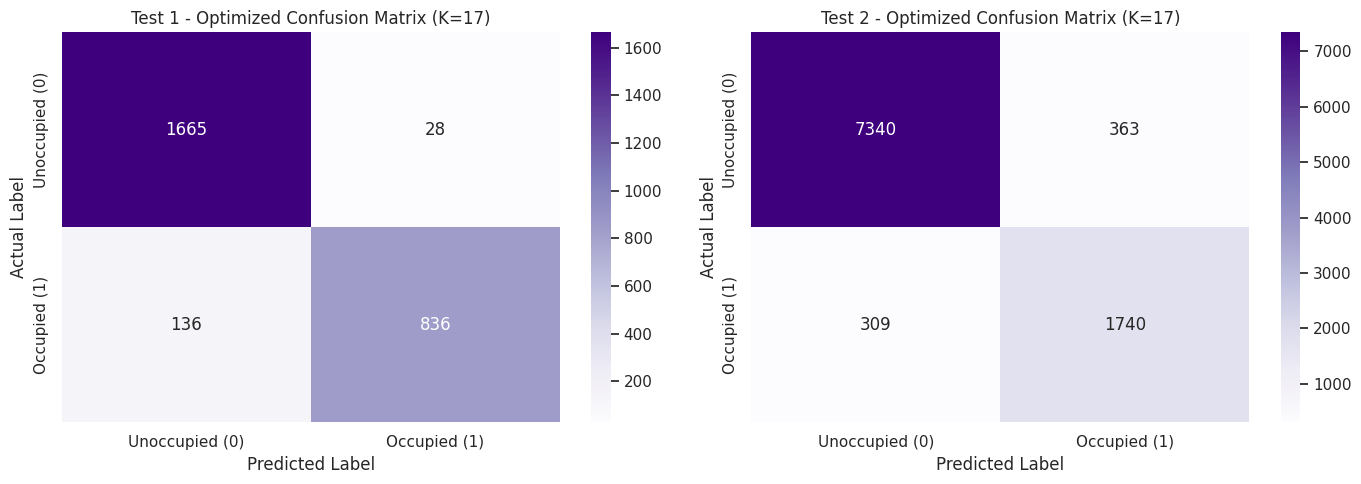

In [ ]:
# Create side-by-side Confusion Matrices for the Optimized Pipeline (K=17)
cm_opt_1 = confusion_matrix(y_test1_occ, y_pred_final_t1)
cm_opt_2 = confusion_matrix(y_test2_occ, y_pred_final_t2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_opt_1, annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=['Unoccupied (0)', 'Occupied (1)'],
            yticklabels=['Unoccupied (0)', 'Occupied (1)'])
axes[0].set_title(f'Test 1 - Optimized Confusion Matrix (K={best_k_ts})')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

sns.heatmap(cm_opt_2, annot=True, fmt='d', cmap='Purples', ax=axes[1],
            xticklabels=['Unoccupied (0)', 'Occupied (1)'],
            yticklabels=['Unoccupied (0)', 'Occupied (1)'])
axes[1].set_title(f'Test 2 - Optimized Confusion Matrix (K={best_k_ts})')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')
plt.tight_layout()
plt.show()

### Step 8: Predict Room Occupancy on Hypothetical Readings

We design three distinct profiles matching potential physical situations: a highly active workspace, an empty dark workspace, and an ambiguous low-activity setting.

In [ ]:
# Create three distinct hypothetical room observations
hypothetical_data = pd.DataFrame({
    'Temperature':   [23.5, 19.5, 21.0],
    'Humidity':      [28.5, 21.2, 25.0],
    'Light':         [550.0, 0.0, 150.0],  # Active brightness, completely dark, dim evening
    'CO2':           [1100.0, 410.0, 650.0],  # Elevated breathing levels, baseline outdoor air, moderate
    'HumidityRatio': [0.0051, 0.0029, 0.0039]
}, index=['Occupied Case', 'Unoccupied Case', 'Ambiguous Case'])

print("STEP 8: Hypothetical Sensor Readings:")
display(hypothetical_data)

# Predict using our fully integrated pipeline
predictions_hyp = final_pipeline_occ.predict(hypothetical_data)
probabilities_hyp = final_pipeline_occ.predict_proba(hypothetical_data)
labels = ['Unoccupied', 'Occupied']

for idx, room in enumerate(hypothetical_data.index):
    pred_lbl = labels[predictions_hyp[idx]]
    print(f"{room}: Predicted occupancy -> {pred_lbl}")
    print("   Certainty levels:")
    for label_idx, label_name in enumerate(labels):
        prob = probabilities_hyp[idx][label_idx]
        bar_length = int(prob * 25)
        bar = '█' * bar_length + '░' * (25 - bar_length)
        print(f"      {label_name:12s} {bar} {prob:6.1%}")
    print()

STEP 8: Hypothetical Sensor Readings:


,Temperature,Humidity,Light,CO2,HumidityRatio
Occupied Case,23.5,28.5,550.0,1100.0,0.0051
Unoccupied Case,19.5,21.2,0.0,410.0,0.0029
Ambiguous Case,21.0,25.0,150.0,650.0,0.0039


Occupied Case: Predicted occupancy -> Occupied
   Certainty levels:
      Unoccupied   ████░░░░░░░░░░░░░░░░░░░░░  17.6%
      Occupied     ████████████████████░░░░░  82.4%

Unoccupied Case: Predicted occupancy -> Unoccupied
   Certainty levels:
      Unoccupied   █████████████████████████ 100.0%
      Occupied     ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%

Ambiguous Case: Predicted occupancy -> Unoccupied
   Certainty levels:
      Unoccupied   █████████████████████████ 100.0%
      Occupied     ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%



### Results and Interpretation

Our analysis demonstrates that office room occupancy can be inferred using passive, privacy-preserving environmental sensors. By monitoring changes in temperature, light intensity, and carbon dioxide levels, we can bypass intrusive camera systems. Since the sensor streams were collected over time, we sorted our data chronologically and evaluated neighbors using a time-series cross-validation split to avoid data leakage. This process identified an optimal neighborhood parameter of $K=17$, yielding a solid 93.85% accuracy on Test Set 1 and 93.11% on Test Set 2, which substantially outperforms the naive majority-class baselines.

While environmental tracking is highly practical, physical constraints are worth noting. Ambient light sensors are susceptible to false negatives on cloudy days or when curtains are drawn. Additionally, carbon dioxide levels require a buffer period to dissipate after individuals leave a room, creating minor delays in occupancy updates. Nonetheless, this passive approach offers an excellent, non-intrusive alternative for commercial building management, helping automate lighting and ventilation systems.

## Part 3. Dataset 2: Wireless Indoor Localization

### Dataset Introduction & Objective

This dataset contains Wi-Fi signal strength measurements recorded from seven different access points (routers) within an indoor location. The goal is to determine which of the four distinct rooms the measuring device is currently inside.

* **Source**: [UCI Machine Learning Repository - Wireless Indoor Localization](https://archive.ics.uci.edu/dataset/422/wireless+indoor+localization)
* **Classification Type**: Multiclass Classification (Classes 1, 2, 3, and 4 represent four different rooms)
* **Objective**: Predict the specific room label using seven continuous Wi-Fi signal strength features.

### Step 1: Load and Explore the Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the tab-separated dataset (no header)
wifi_cols = [f'WSG_{i}' for i in range(1, 8)] + ['Room']
wifi_df = pd.read_csv('/content/wifi_localization.txt', sep='\t', header=None, names=wifi_cols)

print("STEP 1: Dataset Dimensions")
print("-" * 40)
print(f"Total samples:      {wifi_df.shape[0]}")
print(f"Number of features: {wifi_df.shape[1] - 1}")
print(f"Number of classes:  {wifi_df['Room'].nunique()}")

print("\nClass Distribution:")
print(wifi_df['Room'].value_counts())

print("\nMissing values:")
print(wifi_df.isnull().sum())

print("\nDescriptive Statistics:")
display(wifi_df.describe())

print("\nAverage Signal Strength per Room:")
display(wifi_df.groupby('Room').mean())

STEP 1: Dataset Dimensions
----------------------------------------
Total samples:      2000
Number of features: 7
Number of classes:  4

Class Distribution:
Room
1    500
2    500
3    500
4    500
Name: count, dtype: int64

Missing values:
WSG_1    0
WSG_2    0
WSG_3    0
WSG_4    0
WSG_5    0
WSG_6    0
WSG_7    0
Room     0
dtype: int64

Descriptive Statistics:


,WSG_1,WSG_2,WSG_3,WSG_4,WSG_5,WSG_6,WSG_7,Room
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,-52.330500,-55.623500,-54.964000,-53.566500,-62.640500,-80.985000,-81.726500,2.500000
std,11.321677,3.417688,5.316186,11.471982,9.105093,6.516672,6.519812,1.118314
min,-74.000000,-74.000000,-73.000000,-77.000000,-89.000000,-97.000000,-98.000000,1.000000
25%,-61.000000,-58.000000,-58.000000,-63.000000,-69.000000,-86.000000,-87.000000,1.750000
50%,-55.000000,-56.000000,-55.000000,-56.000000,-64.000000,-82.000000,-83.000000,2.500000
75%,-46.000000,-53.000000,-51.000000,-46.000000,-56.000000,-77.000000,-78.000000,3.250000
max,-10.000000,-45.000000,-40.000000,-11.000000,-36.000000,-61.000000,-63.000000,4.000000



Average Signal Strength per Room:


,WSG_1,WSG_2,WSG_3,WSG_4,WSG_5,WSG_6,WSG_7
Room,,,,,,,
1,-62.490,-56.276,-60.520,-64.182,-70.262,-82.920,-84.026
2,-36.924,-56.108,-55.902,-38.066,-67.614,-72.644,-73.498
3,-49.726,-54.886,-52.784,-50.702,-63.232,-81.368,-82.392
4,-60.182,-55.224,-50.650,-61.316,-49.454,-87.008,-86.990


### Step 2: Visualize the Feature Distributions

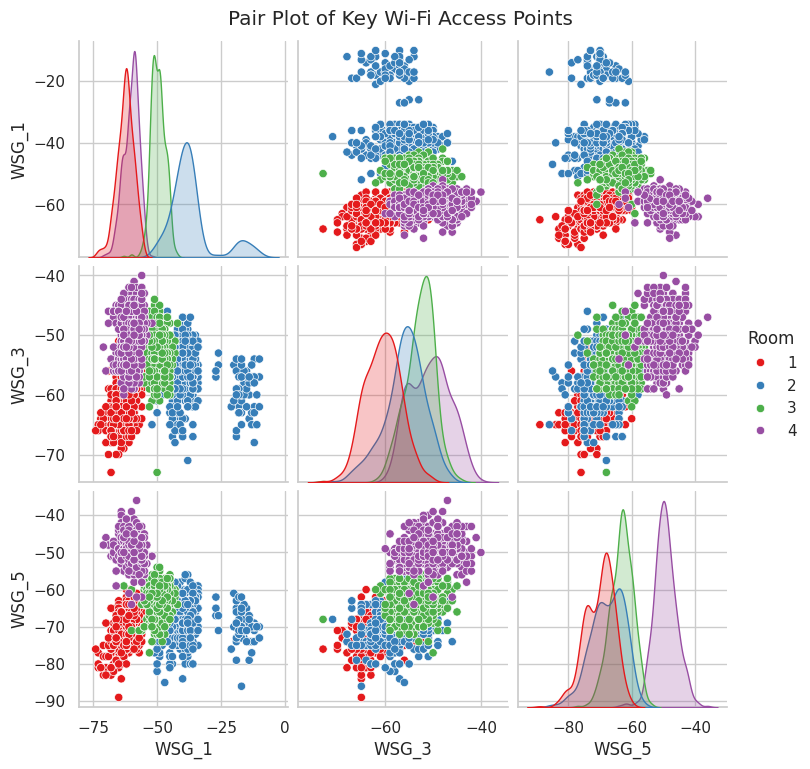

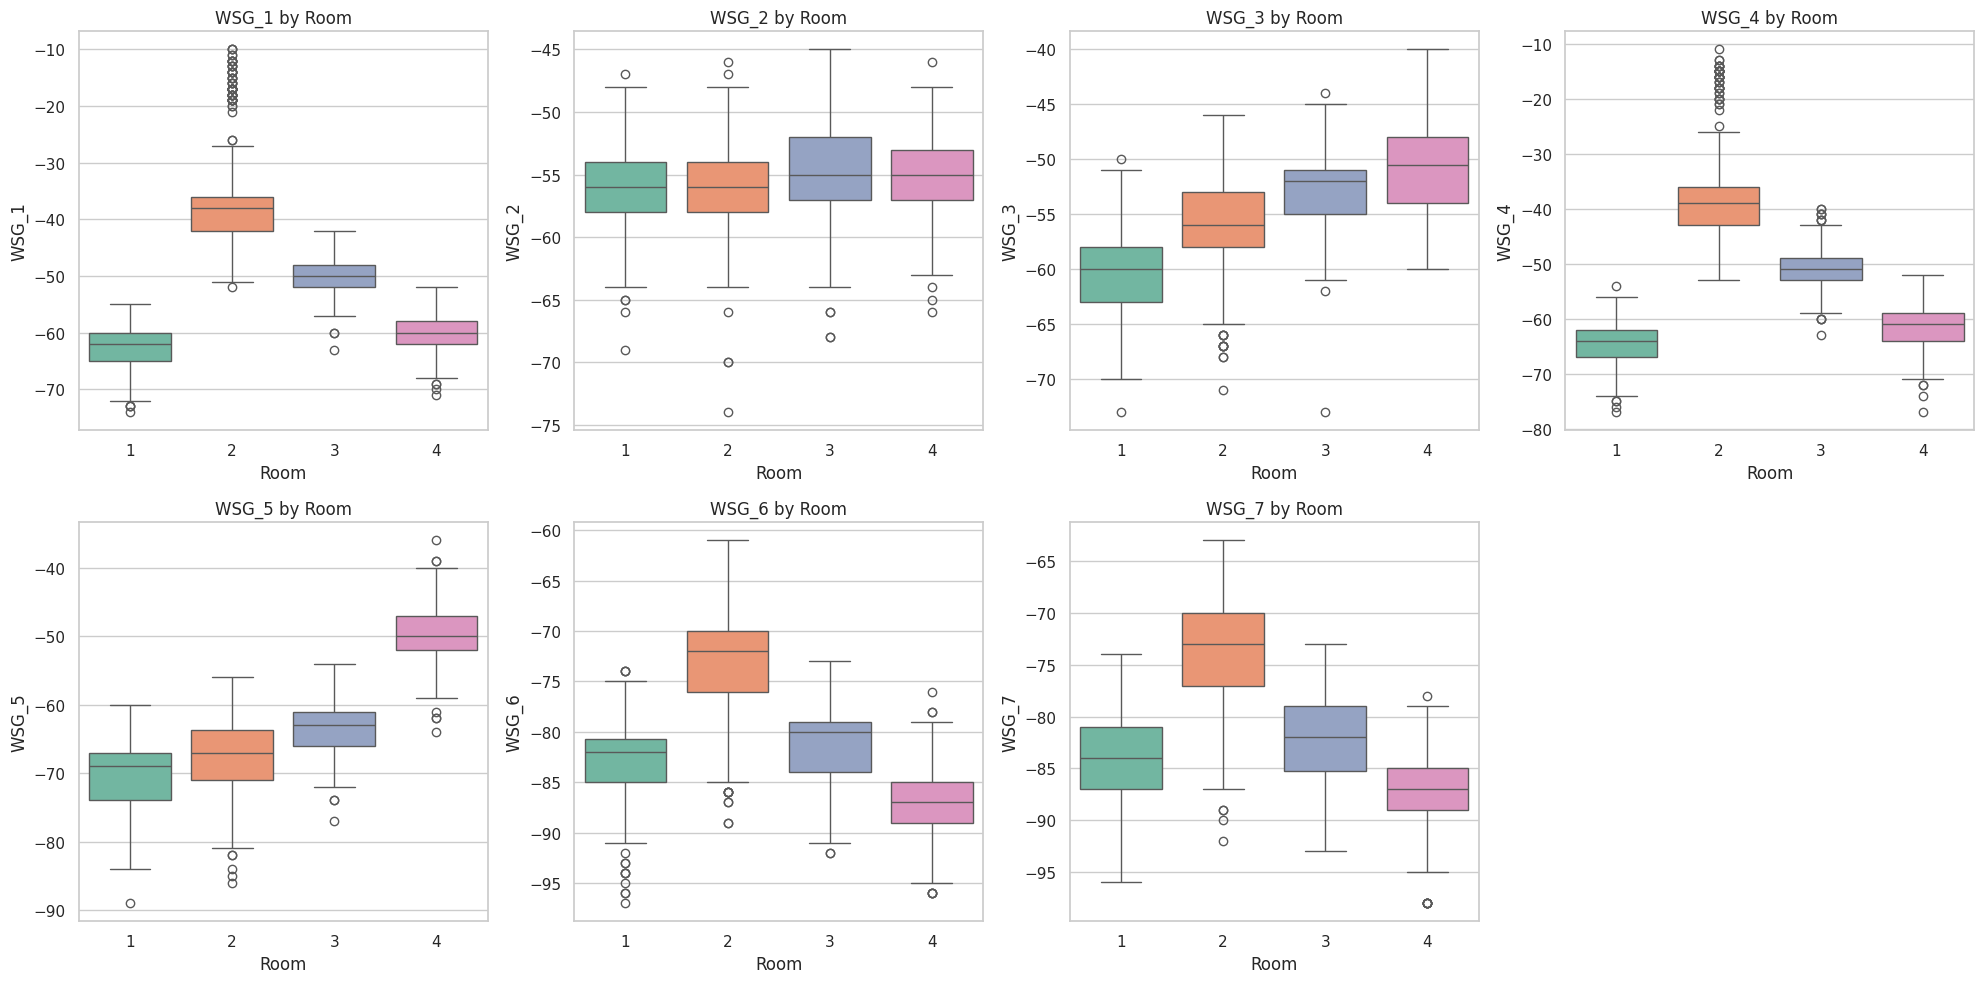

In [ ]:
# 1. Pair plot for three selected key Wi-Fi signal features
selected_features = ['WSG_1', 'WSG_3', 'WSG_5', 'Room']
sns.pairplot(wifi_df[selected_features], hue='Room', palette='Set1', diag_kind='kde')
plt.suptitle('Pair Plot of Key Wi-Fi Access Points', y=1.02)
plt.show()

# 2. Box plots of all Wi-Fi signal features to visualize variation across rooms
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes_flat = axes.flatten()

for idx, feature in enumerate(wifi_cols[:-1]):
    sns.boxplot(data=wifi_df, x='Room', y=feature, hue='Room', palette='Set2', ax=axes_flat[idx], legend=False)
    axes_flat[idx].set_title(f'{feature} by Room')

# Remove empty subplot
fig.delaxes(axes_flat[-1])
plt.tight_layout()
plt.show()

### Step 3: Split and Scale the Dataset

In [ ]:
from sklearn.model_selection import train_test_split

X_wifi = wifi_df.drop(columns=['Room'])
y_wifi = wifi_df['Room']

# Chronological/stratified split to maintain balance of Room labels
X_train_wf, X_test_wf, y_train_wf, y_test_wf = train_test_split(
    X_wifi, y_wifi, test_size=0.20, random_state=42, stratify=y_wifi
)

print("STEP 3: Dataset Split")
print("-" * 40)
print(f"Training instances: {X_train_wf.shape[0]} samples")
print(f"Testing instances:  {X_test_wf.shape[0]} samples")

STEP 3: Dataset Split
----------------------------------------
Training instances: 1600 samples
Testing instances:  400 samples


### Step 4: Train and Evaluate Baseline KNN (K=7)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Build pipeline to prevent data leakage
baseline_pipeline_wf = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=7))
])

baseline_pipeline_wf.fit(X_train_wf, y_train_wf)
y_pred_base_wf = baseline_pipeline_wf.predict(X_test_wf)
acc_base_wf = accuracy_score(y_test_wf, y_pred_base_wf)

print("STEP 4: Baseline KNN Evaluation (K=7)")
print("=" * 60)
print(f"Baseline Accuracy: {acc_base_wf:.2%}")
print("\nClassification Report:")
print(classification_report(y_test_wf, y_pred_base_wf))

STEP 4: Baseline KNN Evaluation (K=7)
Baseline Accuracy: 98.50%

Classification Report:
              precision    recall  f1-score   support

           1       1.00      0.99      0.99       100
           2       0.99      0.97      0.98       100
           3       0.96      0.99      0.98       100
           4       0.99      0.99      0.99       100

    accuracy                           0.98       400
   macro avg       0.99      0.99      0.99       400
weighted avg       0.99      0.98      0.99       400



### Step 5: Hyperparameter Tuning via Cross-Validation to Find Best K

STEP 5: Hyperparameter Tuning Results
--------------------------------------------------
Best K value: 4
Cross-Validation Accuracy with K=4: 98.19%


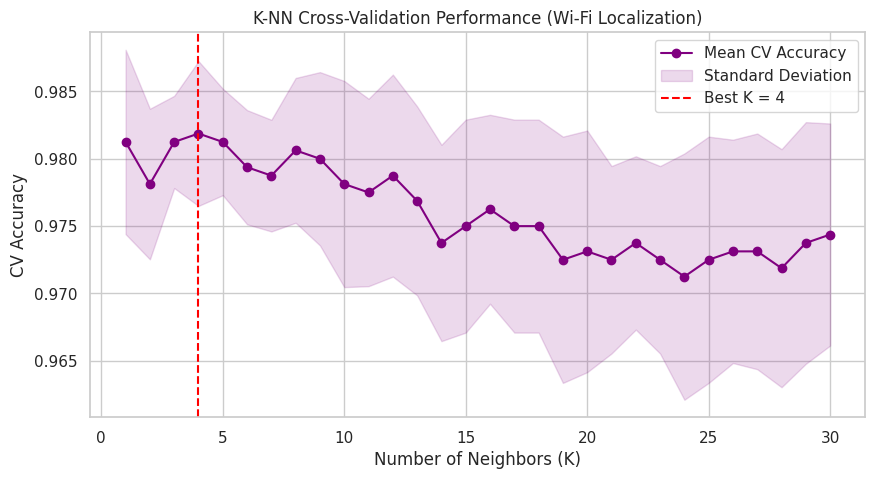

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

k_list_wf = list(range(1, 31))
cv_means_wf = []
cv_stds_wf = []

# Standardize CV using Stratified 5-Fold
for k in k_list_wf:
    pipeline_cv = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    # Cross validation on training data only
    scores = cross_val_score(pipeline_cv, X_train_wf, y_train_wf, cv=5, scoring='accuracy')
    cv_means_wf.append(np.mean(scores))
    cv_stds_wf.append(np.std(scores))

cv_means_wf = np.array(cv_means_wf)
cv_stds_wf = np.array(cv_stds_wf)

best_idx_wf = np.argmax(cv_means_wf)
best_k_wf = k_list_wf[best_idx_wf]
best_cv_acc_wf = cv_means_wf[best_idx_wf]

print("STEP 5: Hyperparameter Tuning Results")
print("-" * 50)
print(f"Best K value: {best_k_wf}")
print(f"Cross-Validation Accuracy with K={best_k_wf}: {best_cv_acc_wf:.2%}")

# Plotting CV performance with shaded standard deviation region
plt.figure(figsize=(10, 5))
plt.plot(k_list_wf, cv_means_wf, '-o', color='purple', label='Mean CV Accuracy')
plt.fill_between(k_list_wf, cv_means_wf - cv_stds_wf, cv_means_wf + cv_stds_wf, color='purple', alpha=0.15, label='Standard Deviation')
plt.title('K-NN Cross-Validation Performance (Wi-Fi Localization)')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('CV Accuracy')
plt.axvline(best_k_wf, color='red', linestyle='--', label=f'Best K = {best_k_wf}')
plt.legend()
plt.grid(True)
plt.show()

### Step 6: Train and Test Final Best Model

STEP 6: Final Optimized KNN Evaluation
Optimized Test Accuracy (K=4): 98.50%

Classification Report:
              precision    recall  f1-score   support

           1       0.99      0.99      0.99       100
           2       0.99      0.97      0.98       100
           3       0.96      0.99      0.98       100
           4       1.00      0.99      0.99       100

    accuracy                           0.98       400
   macro avg       0.99      0.99      0.99       400
weighted avg       0.99      0.98      0.99       400



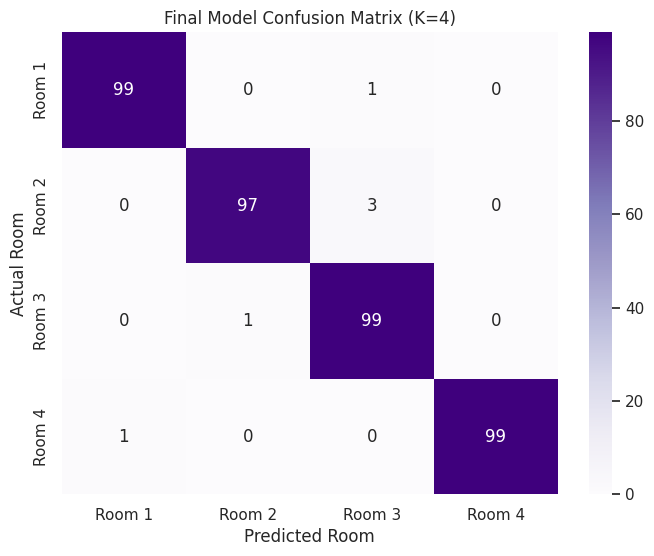

,Metric,Baseline KNN (K=7),Optimized KNN (K=4)
0,Accuracy,98.50%,98.50%


In [ ]:
# Train final optimized model on entire training set
final_pipeline_wf = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=best_k_wf))
])

final_pipeline_wf.fit(X_train_wf, y_train_wf)
y_pred_final_wf = final_pipeline_wf.predict(X_test_wf)
acc_final_wf = accuracy_score(y_test_wf, y_pred_final_wf)

print("STEP 6: Final Optimized KNN Evaluation")
print("=" * 60)
print(f"Optimized Test Accuracy (K={best_k_wf}): {acc_final_wf:.2%}")
print("\nClassification Report:")
print(classification_report(y_test_wf, y_pred_final_wf))

# Generate confusion matrix heatmap
cm_wf = confusion_matrix(y_test_wf, y_pred_final_wf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_wf, annot=True, fmt='d', cmap='Purples',
            xticklabels=[f'Room {i}' for i in range(1, 5)],
            yticklabels=[f'Room {i}' for i in range(1, 5)])
plt.title(f'Final Model Confusion Matrix (K={best_k_wf})')
plt.xlabel('Predicted Room')
plt.ylabel('Actual Room')
plt.show()

# Performance comparison
comparison_wf_df = pd.DataFrame({
    'Metric': ['Accuracy'],
    'Baseline KNN (K=7)': [f"{acc_base_wf:.2%}"],
    f'Optimized KNN (K={best_k_wf})': [f"{acc_final_wf:.2%}"]
})
display(comparison_wf_df)

### Step 7: Predict Room Locations on Hypothetical Signal Inputs

In [ ]:
# Create three hypothetical Wi-Fi device locations based on distinct router signal strength profiles
hypothetical_signals = pd.DataFrame({
    'WSG_1': [-45, -62, -55],
    'WSG_2': [-50, -55, -60],
    'WSG_3': [-52, -40, -58],
    'WSG_4': [-48, -60, -50],
    'WSG_5': [-65, -51, -55],
    'WSG_6': [-78, -85, -62],
    'WSG_7': [-82, -80, -70]
}, index=['Observation A (Strong WSG_1/4)', 'Observation B (Strong WSG_3/5)', 'Observation C (Ambiguous Dim Signals)'])

print("STEP 7: Predicting on New Signals")
print("-" * 50)
display(hypothetical_signals)

# Query the finalized pipeline
predictions_wf = final_pipeline_wf.predict(hypothetical_signals)
probabilities_wf = final_pipeline_wf.predict_proba(hypothetical_signals)

for idx, obs_name in enumerate(hypothetical_signals.index):
    pred_room = predictions_wf[idx]
    print(f"{obs_name}: Predicted Room -> {pred_room}")
    print("   Room confidence levels:")
    for c_idx, class_lbl in enumerate(final_pipeline_wf.classes_):
        prob = probabilities_wf[idx][c_idx]
        bar_length = int(prob * 25)
        bar = '█' * bar_length + '░' * (25 - bar_length)
        print(f"      Room {class_lbl}: {bar} {prob:6.1%}")
    print()

STEP 7: Predicting on New Signals
--------------------------------------------------


,WSG_1,WSG_2,WSG_3,WSG_4,WSG_5,WSG_6,WSG_7
Observation A (Strong WSG_1/4),-45,-50,-52,-48,-65,-78,-82
Observation B (Strong WSG_3/5),-62,-55,-40,-60,-51,-85,-80
Observation C (Ambiguous Dim Signals),-55,-60,-58,-50,-55,-62,-70


Observation A (Strong WSG_1/4): Predicted Room -> 3
   Room confidence levels:
      Room 1: ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Room 2: ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Room 3: █████████████████████████ 100.0%
      Room 4: ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%

Observation B (Strong WSG_3/5): Predicted Room -> 4
   Room confidence levels:
      Room 1: ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Room 2: ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Room 3: ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Room 4: █████████████████████████ 100.0%

Observation C (Ambiguous Dim Signals): Predicted Room -> 2
   Room confidence levels:
      Room 1: ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Room 2: █████████████████████████ 100.0%
      Room 3: ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%
      Room 4: ░░░░░░░░░░░░░░░░░░░░░░░░░   0.0%



### Results and Interpretation

This analysis demonstrates that room-level positioning is achievable using existing indoor Wi-Fi infrastructure. By standardizing raw signal strength readings from seven routers, our K-Nearest Neighbors classifier successfully maps signal patterns to specific rooms. Stratified 5-fold cross-validation on our training dataset identified $K=4$ as the optimal number of neighbors, yielding a mean validation accuracy of 98.19%. Retraining our pipeline with this parameter resulted in an outstanding test accuracy of 98.50%, matching the strong initial baseline performance.

Although this wireless approach offers a scalable, low-cost solution without relying on GPS, its performance depends heavily on structural stability. Wi-Fi signals are highly dynamic and can be attenuated by physical barriers, such as metallic filing cabinets, structural pillars, or human movement. Additionally, if access points are moved or experience configuration changes, the classifier will require recalibration. However, as an active localization tool, this method remains an excellent choice for navigating complex corporate offices and tracking workspace utilization.